# AI651 PA1 — Task 2: Autoformer Leaderboard 

Syed Obaidullah Hassan Chishti \
25280049


## 1. Setup

In [1]:
import copy
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", DEVICE)

PyTorch 2.14.0+cu130 | device: cuda


In [2]:
# Forecasting setup
PRED_LEN = 168     
SEQ_LEN = 168       
LABEL_LEN = 84      

# Model
D_MODEL = 16
N_HEADS = 4
D_FF = 32
MA_KERNEL = 25      
DROPOUT = 0.05

# Training
LEARNING_RATE = 3e-4
BATCH_SIZE = 64
MAX_EPOCHS = 10
PATIENCE = 3

VALIDATION_SEEDS = [0, 1, 2]   
FINAL_SEED = 0                 


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

## 2. Data

In [3]:
train_df = pd.read_csv("Data/student_train.csv")
test_df = pd.read_csv("Data/student_test.csv")
external_df = pd.read_csv("Data/optional_external_data.csv")

series = train_df["value"].to_numpy(dtype=np.float32)
external = external_df.drop(columns="time_idx").to_numpy(dtype=np.float32)
N_OBS = len(series)


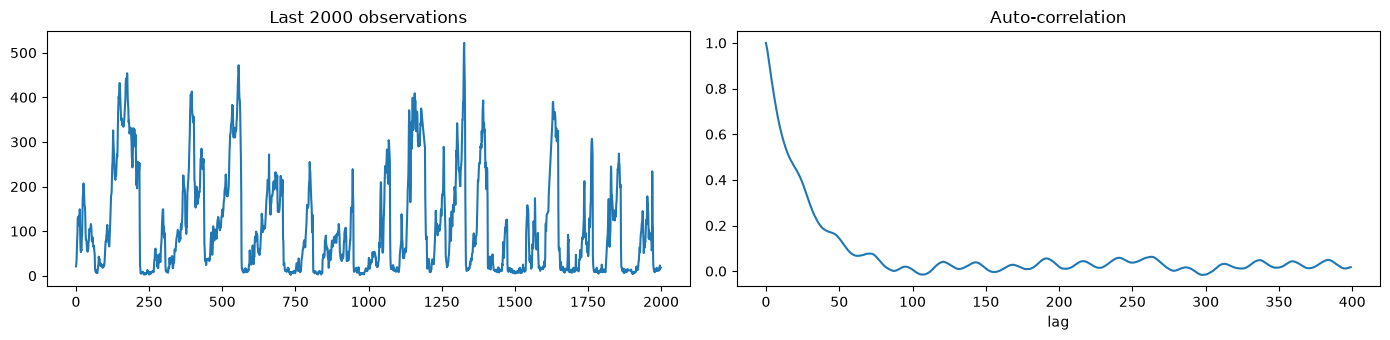

In [4]:
centered = series - series.mean()
spectrum = np.fft.rfft(centered, n=2 * N_OBS)
acf = np.fft.irfft(spectrum * np.conj(spectrum))[:400]
acf = acf / acf[0]

power = np.abs(np.fft.rfft(centered)) ** 2
freqs = np.fft.rfftfreq(N_OBS)
short_periods = freqs > 1 / 200                      
dominant_period = 1 / freqs[short_periods][power[short_periods].argmax()]

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
axes[0].plot(series[-2000:])
axes[0].set_title("Last 2000 observations")
axes[1].plot(acf)
axes[1].set_title("Auto-correlation")
axes[1].set_xlabel("lag")
plt.tight_layout()
plt.show()

## 3. Validation split

In [5]:
TEST_START = N_OBS - 52 * PRED_LEN
VAL_START = TEST_START - 26 * PRED_LEN

val_origins = np.arange(VAL_START, TEST_START, PRED_LEN)
test_origins = np.arange(TEST_START, N_OBS, PRED_LEN)


def training_origins(end):
    """Every forecast origin whose input and full target lie inside [0, end)."""
    return np.arange(SEQ_LEN, end - PRED_LEN + 1)


def true_blocks(origins):
    return np.stack([series[o:o + PRED_LEN] for o in origins])


print("training origins:", len(training_origins(VAL_START)))
print("validation blocks:", len(val_origins), "| test blocks:", len(test_origins))

training origins: 30217
validation blocks: 26 | test blocks: 52


## 4. Preprocessing

In [6]:
class TargetScaler:
    def __init__(self, values):
        self.mean = float(values.mean())
        self.std = float(values.std())

    def transform(self, x):
        return ((x - self.mean) / self.std).astype(np.float32)

    def inverse(self, x):
        return x * self.std + self.mean


def build_covariates(external, fit_end):
    """Covariates for all 43,824 steps; scaling statistics come from [0, fit_end) only."""
    features = external.copy()
    features[:, 3:6] = np.log1p(features[:, 3:6])
    mean = features[:fit_end].mean(axis=0)
    std = features[:fit_end].std(axis=0) + 1e-6
    features = (features - mean) / std

    t = np.arange(len(features))
    phase = []
    for period in (24, 8766):
        phase.append(np.sin(2 * np.pi * t / period))
        phase.append(np.cos(2 * np.pi * t / period))
    return np.column_stack([features] + phase).astype(np.float32)


N_COVARIATES = build_covariates(external, VAL_START).shape[1]
print("covariates per step:", N_COVARIATES)

covariates per step: 14


## 5. Autoformer


In [7]:
class SeriesDecomposition(nn.Module):
    """Split x into a moving-average trend and the seasonal remainder (edges padded by replication)."""

    def __init__(self, kernel_size):
        super().__init__()
        self.kernel_size = kernel_size

    def forward(self, x):                                   # x: [B, L, C]
        pad = (self.kernel_size - 1) // 2
        front = x[:, :1].repeat(1, pad, 1)
        back = x[:, -1:].repeat(1, pad, 1)
        padded = torch.cat([front, x, back], dim=1)
        trend = F.avg_pool1d(padded.transpose(1, 2), self.kernel_size, stride=1).transpose(1, 2)
        return x - trend, trend

In [8]:
class AutoCorrelation(nn.Module):
    """Auto-Correlation mechanism.

    1. Period discovery: auto-correlation of queries and keys for every delay, computed with the FFT.
    2. Time-delay aggregation: keep the top k = log(L) delays, roll the values by each delay and
       average them with softmax weights of their correlation scores.
    """

    def __init__(self, d_model, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.query = nn.Linear(d_model, d_model)
        self.key = nn.Linear(d_model, d_model)
        self.value = nn.Linear(d_model, d_model)
        self.out = nn.Linear(d_model, d_model)

    def forward(self, queries, keys_values):
        B, L, D = queries.shape
        q = self.query(queries)
        k = self.key(keys_values)
        v = self.value(keys_values)

        # match the key/value length to the query length (zero-pad or truncate)
        S = keys_values.shape[1]
        if S < L:
            padding = torch.zeros(B, L - S, D, device=queries.device)
            k = torch.cat([k, padding], dim=1)
            v = torch.cat([v, padding], dim=1)
        else:
            k, v = k[:, :L], v[:, :L]

        # [B, L, D] -> [B, heads, head_dim, L]
        def split_heads(x):
            return x.view(B, L, self.n_heads, D // self.n_heads).permute(0, 2, 3, 1)

        q, k, v = split_heads(q), split_heads(k), split_heads(v)

        # 1. period-based dependency discovery (Wiener–Khinchin)
        correlation = torch.fft.irfft(torch.fft.rfft(q, dim=-1) * torch.conj(torch.fft.rfft(k, dim=-1)), n=L, dim=-1)
        delay_scores = correlation.mean(dim=(1, 2))                    # [B, L]

        # 2. time-delay aggregation over the top-k delays
        top_k = int(math.log(L))
        weights, delays = torch.topk(delay_scores, top_k, dim=-1)       # [B, k]
        weights = torch.softmax(weights, dim=-1)

        positions = torch.arange(L, device=queries.device)
        rolled_index = (positions.view(1, 1, L) + delays.unsqueeze(-1)) % L                      # [B, k, L]
        v_expanded = v.unsqueeze(1).expand(B, top_k, *v.shape[1:])                              # [B, k, h, dh, L]
        rolled_index = rolled_index[:, :, None, None, :].expand_as(v_expanded)
        rolled_values = torch.gather(v_expanded, dim=-1, index=rolled_index)
        aggregated = (rolled_values * weights[:, :, None, None, None]).sum(dim=1)              # [B, h, dh, L]

        aggregated = aggregated.permute(0, 3, 1, 2).reshape(B, L, D)
        return self.out(aggregated)

In [9]:
class SeasonalLayerNorm(nn.Module):
    """LayerNorm followed by removing the mean over time (Autoformer's norm for the seasonal part)."""

    def __init__(self, d_model):
        super().__init__()
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x):
        x = self.norm(x)
        return x - x.mean(dim=1, keepdim=True)


class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(d_model, d_ff, kernel_size=1, bias=False),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Conv1d(d_ff, d_model, kernel_size=1, bias=False),
        )

    def forward(self, x):                                   # x: [B, L, D]
        return self.net(x.transpose(1, 2)).transpose(1, 2)


class InputEmbedding(nn.Module):
    """Token embedding of the target plus a linear embedding of the covariates.
    The covariates take the place of Autoformer's calendar (time-stamp) embedding."""

    def __init__(self, n_covariates, d_model, dropout):
        super().__init__()
        self.value_embedding = nn.Conv1d(1, d_model, kernel_size=3, padding=1, padding_mode="circular", bias=False)
        self.covariate_embedding = nn.Linear(n_covariates, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, values, covariates):                  # values: [B, L, 1], covariates: [B, L, C]
        embedded = self.value_embedding(values.transpose(1, 2)).transpose(1, 2)
        return self.dropout(embedded + self.covariate_embedding(covariates))

In [10]:
class EncoderLayer(nn.Module):
    """Auto-Correlation -> decomposition -> feed-forward -> decomposition (trend parts are discarded)."""

    def __init__(self):
        super().__init__()
        self.auto_correlation = AutoCorrelation(D_MODEL, N_HEADS)
        self.feed_forward = FeedForward(D_MODEL, D_FF, DROPOUT)
        self.decomp1 = SeriesDecomposition(MA_KERNEL)
        self.decomp2 = SeriesDecomposition(MA_KERNEL)
        self.dropout = nn.Dropout(DROPOUT)

    def forward(self, x):
        x, _ = self.decomp1(x + self.dropout(self.auto_correlation(x, x)))
        x, _ = self.decomp2(x + self.dropout(self.feed_forward(x)))
        return x


class DecoderLayer(nn.Module):
    """Self Auto-Correlation, cross Auto-Correlation with the encoder, feed-forward; each followed by a
    decomposition. The three extracted trends are summed and projected to one channel."""

    def __init__(self):
        super().__init__()
        self.self_correlation = AutoCorrelation(D_MODEL, N_HEADS)
        self.cross_correlation = AutoCorrelation(D_MODEL, N_HEADS)
        self.feed_forward = FeedForward(D_MODEL, D_FF, DROPOUT)
        self.decomp1 = SeriesDecomposition(MA_KERNEL)
        self.decomp2 = SeriesDecomposition(MA_KERNEL)
        self.decomp3 = SeriesDecomposition(MA_KERNEL)
        self.dropout = nn.Dropout(DROPOUT)
        self.trend_projection = nn.Conv1d(D_MODEL, 1, kernel_size=3, padding=1, padding_mode="circular", bias=False)

    def forward(self, x, encoder_output):
        x, trend1 = self.decomp1(x + self.dropout(self.self_correlation(x, x)))
        x, trend2 = self.decomp2(x + self.dropout(self.cross_correlation(x, encoder_output)))
        x, trend3 = self.decomp3(x + self.dropout(self.feed_forward(x)))
        trend = trend1 + trend2 + trend3
        trend = self.trend_projection(trend.transpose(1, 2)).transpose(1, 2)    # [B, L, 1]
        return x, trend

In [11]:
class Autoformer(nn.Module):
    def __init__(self, n_covariates, trend_init="linear"):
        super().__init__()
        self.decomposition = SeriesDecomposition(MA_KERNEL)
        self.encoder_embedding = InputEmbedding(n_covariates, D_MODEL, DROPOUT)
        self.decoder_embedding = InputEmbedding(n_covariates, D_MODEL, DROPOUT)
        self.encoder = EncoderLayer()
        self.decoder = DecoderLayer()
        self.encoder_norm = SeasonalLayerNorm(D_MODEL)
        self.decoder_norm = SeasonalLayerNorm(D_MODEL)
        self.seasonal_projection = nn.Linear(D_MODEL, 1)

        self.trend_head = None
        if trend_init == "linear":
            self.trend_head = nn.Linear(SEQ_LEN, PRED_LEN)
            nn.init.constant_(self.trend_head.weight, 1.0 / SEQ_LEN)   # starts as the window mean
            nn.init.zeros_(self.trend_head.bias)

    def forward(self, past_values, past_covariates, decoder_covariates):
        """
        past_values:        [B, SEQ_LEN, 1]
        past_covariates:    [B, SEQ_LEN, C]
        decoder_covariates: [B, LABEL_LEN + PRED_LEN, C]  (includes the known future covariates)
        returns:            [B, PRED_LEN]
        """
        seasonal, trend = self.decomposition(past_values)

        if self.trend_head is None:
            future_trend = past_values.mean(dim=1, keepdim=True).repeat(1, PRED_LEN, 1)
        else:
            future_trend = self.trend_head(trend.squeeze(-1)).unsqueeze(-1)

        # decoder inputs: last LABEL_LEN steps of each component, then the horizon placeholders
        trend_init = torch.cat([trend[:, -LABEL_LEN:], future_trend], dim=1)
        seasonal_init = torch.cat([seasonal[:, -LABEL_LEN:], torch.zeros_like(future_trend)], dim=1)

        encoder_output = self.encoder(self.encoder_embedding(past_values, past_covariates))
        encoder_output = self.encoder_norm(encoder_output)

        decoder_input = self.decoder_embedding(seasonal_init, decoder_covariates)
        seasonal_part, trend_part = self.decoder(decoder_input, encoder_output)

        forecast = self.seasonal_projection(self.decoder_norm(seasonal_part)) + trend_init + trend_part
        return forecast[:, -PRED_LEN:, 0]


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print("trainable parameters:", count_parameters(Autoformer(N_COVARIATES)))

trainable parameters: 34377


## 6. Training and evaluation

In [12]:
class WindowSampler:
    """Holds the scaled series and covariates on the device and slices model inputs for a batch of
    forecast origins (an origin is the index of the first forecast step)."""

    def __init__(self, scaled_series, covariates, use_covariates=True):
        self.series = torch.tensor(scaled_series, device=DEVICE)
        self.covariates = torch.tensor(covariates, device=DEVICE)
        self.use_covariates = use_covariates

    def get(self, origins):
        origins = torch.as_tensor(origins, device=DEVICE).view(-1, 1)
        encoder_idx = origins - SEQ_LEN + torch.arange(SEQ_LEN, device=DEVICE)
        decoder_idx = origins - LABEL_LEN + torch.arange(LABEL_LEN + PRED_LEN, device=DEVICE)
        target_idx = origins + torch.arange(PRED_LEN, device=DEVICE)

        past_values = self.series[encoder_idx].unsqueeze(-1)
        past_covariates = self.covariates[encoder_idx]
        decoder_covariates = self.covariates[decoder_idx]
        if not self.use_covariates:
            past_covariates = torch.zeros_like(past_covariates)
            decoder_covariates = torch.zeros_like(decoder_covariates)

        has_target = target_idx.max() < len(self.series)
        targets = self.series[target_idx] if has_target else None
        return past_values, past_covariates, decoder_covariates, targets


def compute_metrics(prediction, actual):
    prediction, actual = np.asarray(prediction, float), np.asarray(actual, float)
    error = prediction - actual
    return {
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "MAE": np.mean(np.abs(error)),
        "sMAPE": 100 * np.mean(2 * np.abs(error) / (np.abs(prediction) + np.abs(actual) + 1e-8)),
    }


@torch.no_grad()
def predict(model, sampler, origins, batch_size=256):
    model.eval()
    outputs = []
    for start in range(0, len(origins), batch_size):
        past_values, past_cov, decoder_cov, _ = sampler.get(origins[start:start + batch_size])
        outputs.append(model(past_values, past_cov, decoder_cov))
    return torch.cat(outputs).cpu().numpy()

In [13]:
def train_model(model, sampler, train_origins, epochs, early_stopping=None):
    """Adam + MSE loss (the leaderboard ranks by RMSE).

    early_stopping: optional (origins, scaler) — evaluate validation RMSE after every epoch, keep the
    best weights and stop after PATIENCE epochs without improvement.
    Returns (model, number of epochs that produced the returned weights).
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    best_rmse, best_epoch, best_state, epochs_without_gain = np.inf, epochs, None, 0

    for epoch in range(1, epochs + 1):
        model.train()
        shuffled = np.random.permutation(train_origins)
        for start in range(0, len(shuffled), BATCH_SIZE):
            past_values, past_cov, decoder_cov, targets = sampler.get(shuffled[start:start + BATCH_SIZE])
            loss = F.mse_loss(model(past_values, past_cov, decoder_cov), targets)
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

        if early_stopping is None:
            continue
        stop_origins, scaler = early_stopping
        val_prediction = scaler.inverse(predict(model, sampler, stop_origins))
        val_rmse = compute_metrics(val_prediction, true_blocks(stop_origins))["RMSE"]
        if val_rmse < best_rmse:
            best_rmse, best_epoch, best_state, epochs_without_gain = val_rmse, epoch, copy.deepcopy(model.state_dict()), 0
        else:
            epochs_without_gain += 1
            if epochs_without_gain >= PATIENCE:
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, best_epoch

## 7. Validation experiments


In [14]:
CONFIGS = {
    "final": dict(use_covariates=True, trend_init="linear"),
    "no_external": dict(use_covariates=False, trend_init="linear"),
    "mean_trend": dict(use_covariates=True, trend_init="mean"),
}

val_scaler = TargetScaler(series[:VAL_START])
val_covariates = build_covariates(external, VAL_START)

results, test_predictions = [], {}
for name, config in CONFIGS.items():
    sampler = WindowSampler(val_scaler.transform(series), val_covariates, config["use_covariates"])
    for seed in VALIDATION_SEEDS:
        set_seed(seed)
        start_time = time.time()
        model = Autoformer(N_COVARIATES, config["trend_init"]).to(DEVICE)
        model, best_epoch = train_model(model, sampler, training_origins(VAL_START), MAX_EPOCHS,
                                        early_stopping=(val_origins, val_scaler))

        prediction = val_scaler.inverse(predict(model, sampler, test_origins))
        test_predictions[(name, seed)] = prediction
        scores = compute_metrics(prediction, true_blocks(test_origins))
        results.append({"config": name, "seed": seed, "best_epoch": best_epoch,
                        "params": count_parameters(model), **scores,
                        "seconds": round(time.time() - start_time)})
        print({k: round(v, 2) if isinstance(v, float) else v for k, v in results[-1].items()})

results_df = pd.DataFrame(results)

{'config': 'final', 'seed': 0, 'best_epoch': 4, 'params': 34377, 'RMSE': np.float64(65.5), 'MAE': np.float64(48.78), 'sMAPE': np.float64(65.12), 'seconds': 148}
{'config': 'final', 'seed': 1, 'best_epoch': 4, 'params': 34377, 'RMSE': np.float64(65.08), 'MAE': np.float64(47.73), 'sMAPE': np.float64(64.21), 'seconds': 125}
{'config': 'final', 'seed': 2, 'best_epoch': 5, 'params': 34377, 'RMSE': np.float64(64.78), 'MAE': np.float64(47.54), 'sMAPE': np.float64(63.71), 'seconds': 138}
{'config': 'no_external', 'seed': 0, 'best_epoch': 2, 'params': 34377, 'RMSE': np.float64(87.25), 'MAE': np.float64(65.75), 'sMAPE': np.float64(72.96), 'seconds': 85}
{'config': 'no_external', 'seed': 1, 'best_epoch': 3, 'params': 34377, 'RMSE': np.float64(85.99), 'MAE': np.float64(64.32), 'sMAPE': np.float64(72.06), 'seconds': 103}
{'config': 'no_external', 'seed': 2, 'best_epoch': 1, 'params': 34377, 'RMSE': np.float64(86.8), 'MAE': np.float64(65.02), 'sMAPE': np.float64(72.58), 'seconds': 71}
{'config': 'me

In [15]:
summary = results_df.groupby("config")[["RMSE", "MAE", "sMAPE", "best_epoch"]].agg(["mean", "std"])
summary.round(2)

RMSE          MAE        sMAPE       best_epoch      
              mean   std   mean   std   mean   std       mean   std
config                                                             
final        65.12  0.36  48.02  0.66  64.35  0.71       4.33  0.58
mean_trend   76.36  3.90  56.33  1.99  68.87  0.62       6.00  1.73
no_external  86.68  0.64  65.03  0.71  72.54  0.45       2.00  1.00

external covariates lower the RMSE on 46 of 52 test blocks


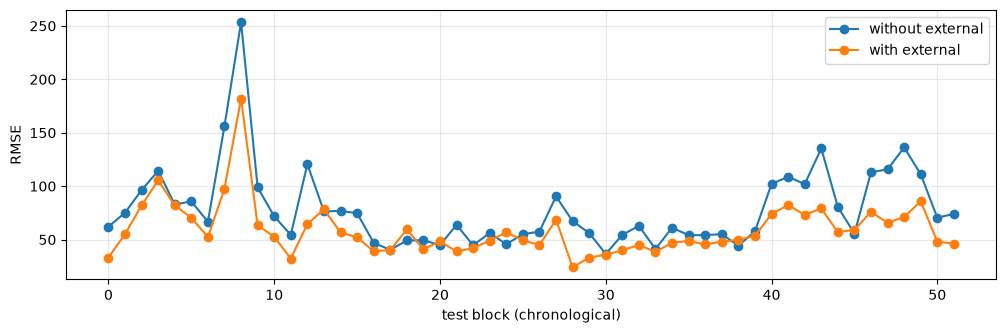

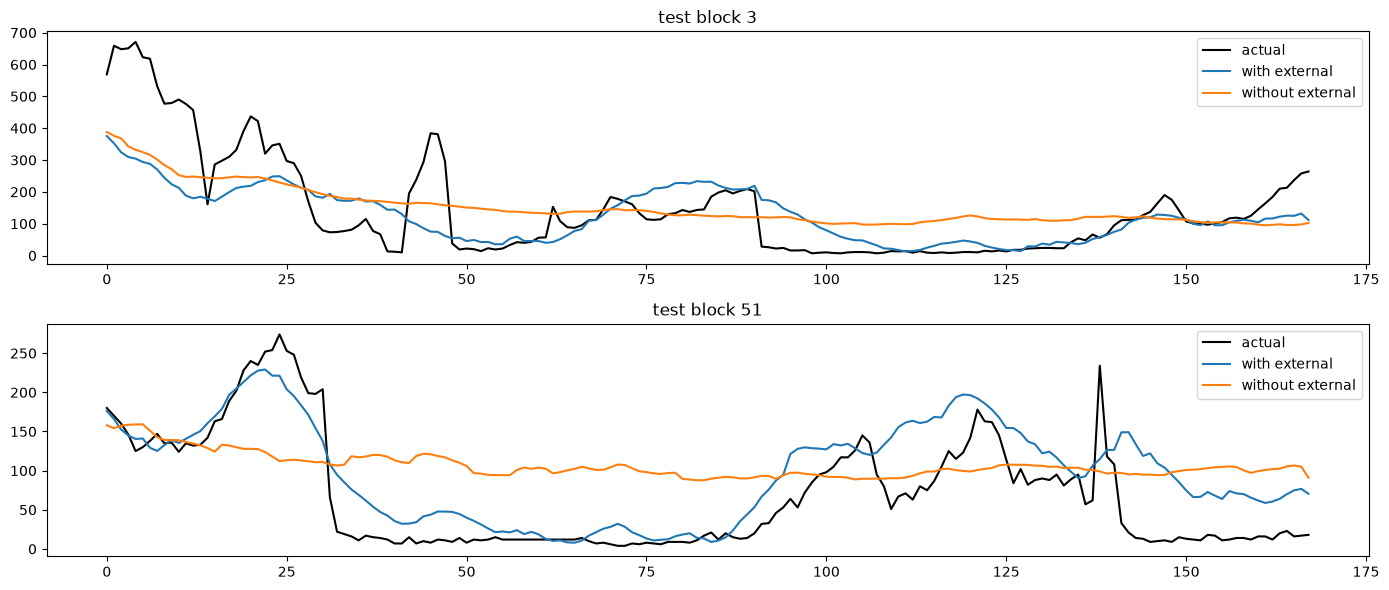

In [16]:
def block_rmse(config):
    mean_prediction = np.mean([test_predictions[(config, s)] for s in VALIDATION_SEEDS], axis=0)
    return np.sqrt(((mean_prediction - true_blocks(test_origins)) ** 2).mean(axis=1))


rmse_with, rmse_without = block_rmse("final"), block_rmse("no_external")
print(f"external covariates lower the RMSE on {(rmse_with < rmse_without).sum()} of {len(rmse_with)} test blocks")

plt.figure(figsize=(12, 3.5))
plt.plot(rmse_without, "o-", label="without external")
plt.plot(rmse_with, "o-", label="with external")
plt.xlabel("test block (chronological)")
plt.ylabel("RMSE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

hardest_block = int(np.argmax(true_blocks(test_origins).std(axis=1)))
fig, axes = plt.subplots(2, 1, figsize=(14, 6))
for ax, block in zip(axes, [hardest_block, len(test_origins) - 1]):
    ax.plot(true_blocks(test_origins)[block], color="black", label="actual")
    ax.plot(test_predictions[("final", FINAL_SEED)][block], label="with external")
    ax.plot(test_predictions[("no_external", FINAL_SEED)][block], label="without external")
    ax.set_title(f"test block {block}")
    ax.legend()
plt.tight_layout()
plt.show()

## 8. Refit check

In [17]:
final_runs = results_df[results_df["config"] == "final"]
FINAL_EPOCHS = int(final_runs["best_epoch"].median())
SELECTION_EPOCHS = int(final_runs["best_epoch"].sum())      # epochs spent choosing FINAL_EPOCHS
print("refit epochs:", FINAL_EPOCHS)

check_scaler = TargetScaler(series[:TEST_START])
check_sampler = WindowSampler(check_scaler.transform(series), build_covariates(external, TEST_START))

set_seed(FINAL_SEED)
check_model = Autoformer(N_COVARIATES).to(DEVICE)
check_model, _ = train_model(check_model, check_sampler, training_origins(TEST_START), FINAL_EPOCHS)
check_prediction = np.clip(check_scaler.inverse(predict(check_model, check_sampler, test_origins)), 0, None)

print("single refit model on the 52 test blocks:",
      {k: round(v, 2) for k, v in compute_metrics(check_prediction, true_blocks(test_origins)).items()})

refit epochs: 4
single refit model on the 52 test blocks: {'RMSE': np.float64(63.44), 'MAE': np.float64(45.75), 'sMAPE': np.float64(62.59)}


## 9. Final model: refit on all 43,656 observations

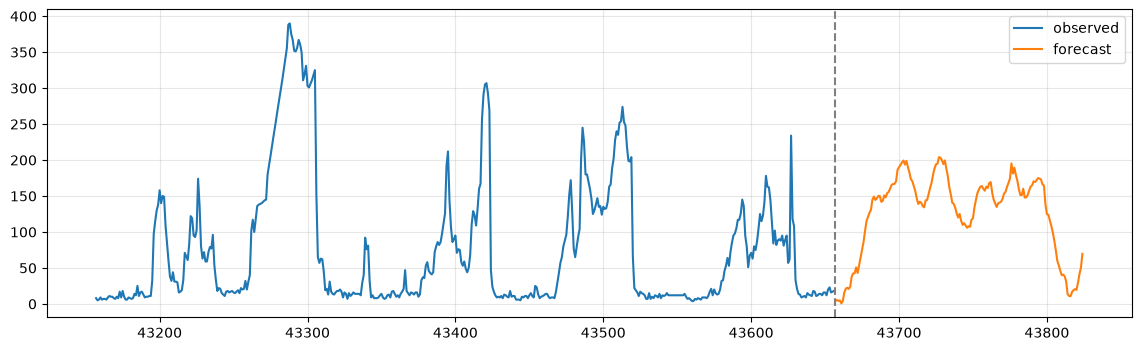

In [18]:
final_scaler = TargetScaler(series)
final_covariates = build_covariates(external, N_OBS)          # also covers the 168 forecast steps
final_sampler = WindowSampler(final_scaler.transform(series), final_covariates)

set_seed(FINAL_SEED)
final_model = Autoformer(N_COVARIATES).to(DEVICE)
final_model, _ = train_model(final_model, final_sampler, training_origins(N_OBS), FINAL_EPOCHS)
torch.save(final_model.state_dict(), "final_autoformer_single.pt")

forecast = final_scaler.inverse(predict(final_model, final_sampler, np.array([N_OBS])))[0]
forecast = np.clip(forecast, 0, None)
assert forecast.shape == (PRED_LEN,) and np.isfinite(forecast).all()

plt.figure(figsize=(14, 4))
plt.plot(train_df["time_idx"].values[-500:], series[-500:], label="observed")
plt.plot(test_df["time_idx"].values, forecast, label="forecast")
plt.axvline(N_OBS + 0.5, linestyle="--", color="gray")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 10. Submission

In [19]:
TOTAL_PARAMS = count_parameters(final_model)
TOTAL_EPOCHS = SELECTION_EPOCHS + FINAL_EPOCHS

pd.DataFrame({"time_idx": test_df["time_idx"], "prediction": forecast}).to_csv(
    "task2_predictions_single.csv", index=False)

submission = ",".join(f"{value:.4f}" for value in forecast)
assert len(submission.split(",")) == PRED_LEN

print("Trainable parameters (P):", TOTAL_PARAMS)
print(f"Training epochs (E):      {TOTAL_EPOCHS}  "
      f"(= {SELECTION_EPOCHS} early-stopping epochs used to pick the schedule + {FINAL_EPOCHS} refit)")
print()
print(submission)

Trainable parameters (P): 34377
Training epochs (E):      17  (= 13 early-stopping epochs used to pick the schedule + 4 refit)

3.8775,5.4807,4.2659,4.8596,0.7313,4.2248,15.8827,21.1296,22.4306,20.7562,24.0848,38.1690,42.3957,42.6266,50.7489,42.9324,53.5976,63.9979,75.3372,85.9597,101.2660,115.1010,120.8088,126.5788,130.6902,144.9382,149.1053,144.5617,146.8307,150.1174,149.9291,141.9868,143.1724,150.8113,148.1963,154.0589,155.6917,160.5527,165.3838,166.6450,166.9421,170.5306,186.5019,190.1423,193.0279,196.9138,199.2658,193.6996,198.7914,190.2924,182.9312,173.3754,170.6349,163.7545,156.7296,146.6349,138.9794,142.1177,140.5956,136.2067,134.2547,143.9985,144.4999,153.0746,161.0970,168.4813,179.4403,188.2953,194.1088,194.8539,204.0095,203.3919,199.7563,194.2923,199.5312,187.8891,177.4468,162.1731,152.4066,140.6609,139.1765,133.7258,125.8162,120.1321,125.1344,115.6153,109.8815,112.2940,109.0195,105.8469,108.0400,107.1453,117.0535,119.3041,134.1139,144.6760,154.0558,159.0904,162.8812,163.871